<a href="https://colab.research.google.com/github/pelamiguelpr/pelamiguelpr-DataSience-GenAI-Submissions/blob/main/Assignment_5/2_05_Exploratory_Data_Analysis_COMPLETED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 2.05 Exploratory Data Analysis (EDA)
We have seen some early examples of EDA in the previous notebooks. This session will expand on this with more examples - specifically a dataset on student performance. You can find the data on my.wbs as "students.csv" (in week 3, asynchronous tasks). As such, we start by importing the data:

EDA on the Titanic dataset, which records passenger details and survival outcomes for 891 passengers.

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving titanic.csv to titanic (1).csv


We can now import the data into pandas as before:

In [37]:
titanic = pd.read_csv('titanic.csv')
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


We can find the number of rows and columns with ".shape":

In [38]:
titanic.shape

(891, 12)

891 rows and 12 columns. We can get more information about the data using the info() function:

In [39]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


The columns are of type object (text, such as Name and Sex), int64 (whole numbers, such as Pclass) or float64 (decimals, such as Age and Fare). Unlike the students data, not every column has 891 non-null values: Age has 714, Cabin only 204 and Embarked 889. This suggests missing data, which we can confirm:

In [40]:
titanic.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


There are missing values in three columns: 177 in Age, 687 in Cabin and 2 in Embarked. To decide how to treat each one, it helps to see the percentage missing:

In [41]:
# Percent of data which is not available
titanic.isnull().sum()/len(titanic) * 100

,0
PassengerId,0.000000
Survived,0.000000
Pclass,0.000000
Name,0.000000
Sex,0.000000
Age,19.865320
SibSp,0.000000
Parch,0.000000
Ticket,0.000000
Fare,0.000000


Cabin is around 77% missing, so it is unlikely to be useful and is a candidate for removal. Age is around 20% missing, which is significant, but the variable is too important to drop. Embarked is missing only 2 values, which could simply be filled with the most common port. We can also check for duplicate rows:

In [42]:
   titanic = titanic.drop(['Cabin'], axis=1)
   titanic['Age'] = titanic['Age'].fillna(titanic['Age'].median())
   titanic['Embarked'] = titanic['Embarked'].fillna(titanic['Embarked'].mode()[0])
   titanic.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [43]:
titanic.duplicated().value_counts()

,count
False,891


There are no duplicates (all 891 records return False). Pandas can also give us summary statistics:

In [44]:
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Only the numeric columns are described. A few points stand out. The mean of Survived is around 0.38, meaning only about 38% of passengers survived. Fare is heavily skewed: the median is around £14, but the mean is over £32 and the maximum over £500, so a small number of passengers paid far more than the rest. PassengerId is also described, although as an identifier its statistics have no meaning.

### Visualising the Data

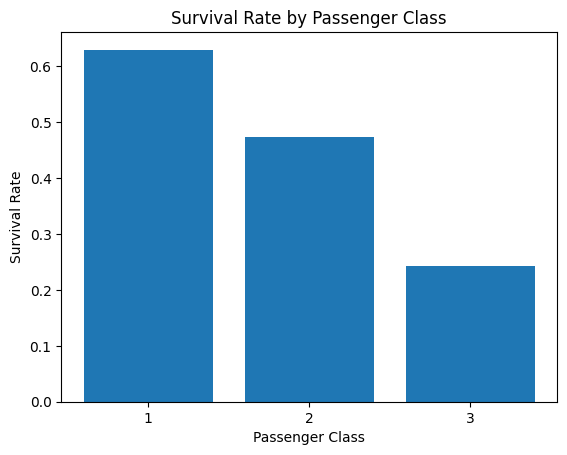

In [45]:
survival_by_class = titanic.groupby('Pclass')['Survived'].mean()

plt.bar(survival_by_class.index.astype(str), survival_by_class.values)
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.title('Survival Rate by Passenger Class')
plt.show()

Survival clearly depended on class: around 63% of first-class passengers survived, compared with about 47% in second class and only 24% in third. Note that the chart shows the average survival rate per class, calculated with groupby(), rather than plotting every passenger on top of each other.

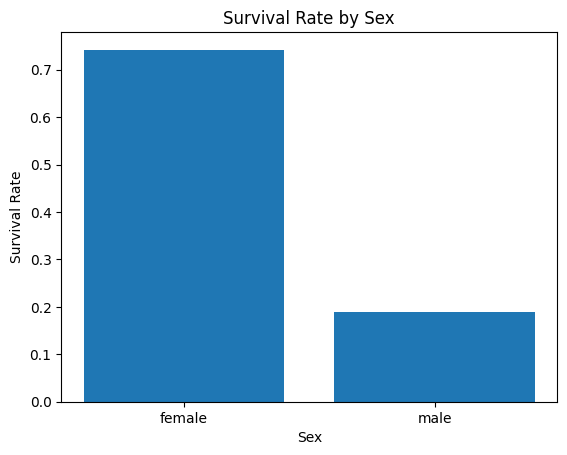

In [46]:
survival_by_sex = titanic.groupby('Sex')['Survived'].mean()

plt.bar(survival_by_sex.index, survival_by_sex.values)
plt.xlabel('Sex')
plt.ylabel('Survival Rate')
plt.title('Survival Rate by Sex')
plt.show()

The difference by sex is even larger: around 74% of women survived, compared with about 19% of men, which is consistent with the “women and children first” policy. Let’s look at the relationship between two numeric variables:

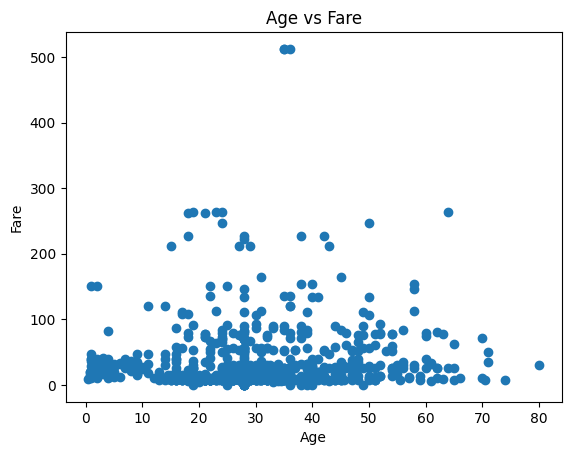

In [47]:
plt.scatter(titanic['Age'], titanic['Fare'])
plt.xlabel('Age')
plt.ylabel('Fare')
plt.title('Age vs Fare')
plt.show()

No clear relationship

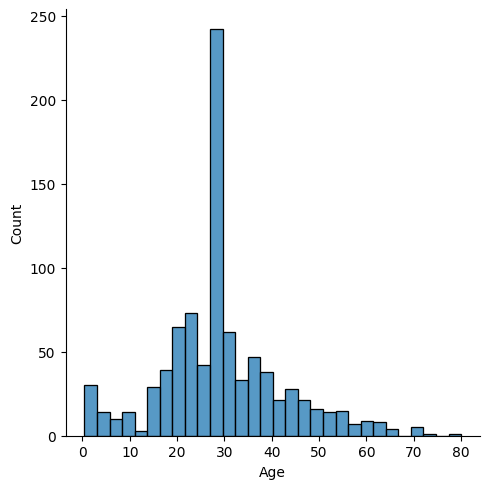

In [48]:
ax = sns.displot(titanic['Age'], bins=30)

Age is roughly normal, though slightly right-skewed, with most passengers aged between 20 and 40 and a smaller group of young children.

We can use the _pairplot( )_ method to visualise pairs of variables:

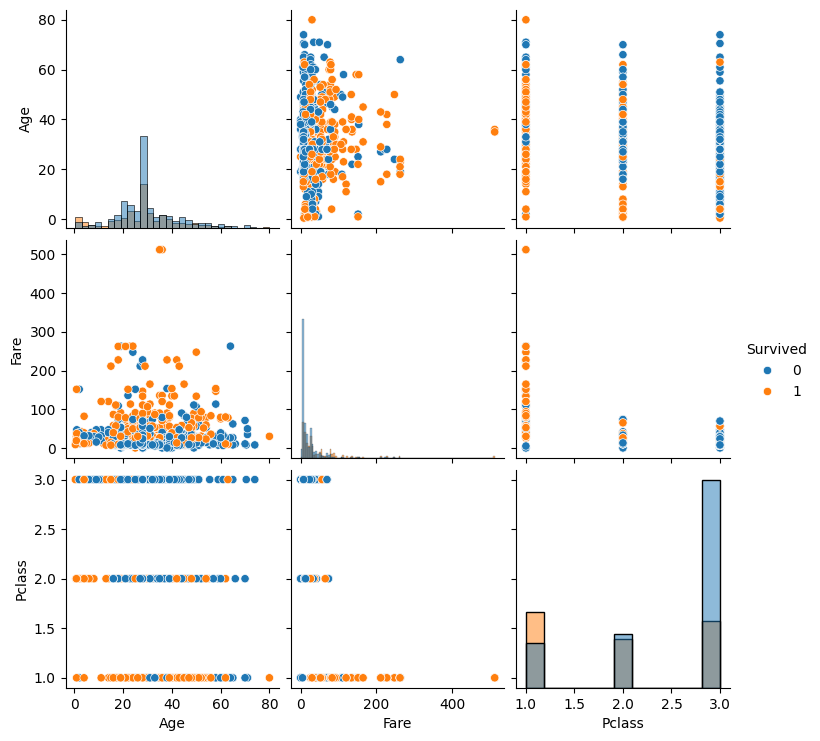

In [49]:
sns.pairplot(data=titanic[['Age', 'Fare', 'Pclass', 'Survived']], hue='Survived', diag_kind='hist')

The pair plot shows each pair of variables as a scatter plot and each single variable as a histogram, with survivors and non-survivors coloured separately. Survivors are more common among first-class passengers and at higher fares. We can put a number on these relationships with a correlation matrix:

In [50]:
titanic[['Survived', 'Pclass', 'Age', 'Fare']].corr().round(2)

,Survived,Pclass,Age,Fare
Survived,1.00,-0.34,-0.06,0.26
Pclass,-0.34,1.00,-0.34,-0.55
Age,-0.06,-0.34,1.00,0.10
Fare,0.26,-0.55,0.10,1.00


Survival is negatively correlated with Pclass (around −0.34): the higher the class number, i.e. third class, the lower the chance of survival. It is positively correlated with Fare (around 0.26), which reflects the same pattern, since wealthier passengers travelled in higher classes. Age has only a weak relationship with survival. Finally, we can remove variables that add nothing to the analysis:

In [51]:
titanic = titanic.drop(['PassengerId', 'Name', 'Ticket'], axis=1)
titanic.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


PassengerId, Name and Ticket are identifiers or free text, so they are not useful for analysis and have been removed.